# Qualidade das datas do SINAN para chikungunya

Este notebook avalia a qualidade das sete colunas de data presentes no dataset tratado de casos internados por chikungunya.
O objetivo é medir a taxa de falha de conversão para datetime, verificar a consistência lógica esperada entre as datas, checar a relação entre a data de óbito e o desfecho, e resumir o tempo entre o início dos sintomas e a notificação.
Os dados de entrada já foram tratados pelo pipeline do projeto e são lidos diretamente de `data/processed/chik_treated.parquet`, sem reaplicar nenhuma etapa de limpeza aqui.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
RESULTS_DIR = PROJECT_ROOT / "analysis" / "results_diagnostico"
PLOTS_DIR = PROJECT_ROOT / "analysis" / "plots" / "diagnostico"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

Carrega o dataset tratado produzido pelo pipeline do projeto.
As colunas de data armazenam string vazia quando o valor é ausente na ficha de notificação original, de modo que a string vazia é substituída por valor nulo antes de qualquer análise.

In [2]:
DATE_COLS = [
    "DT_NOTIFIC",
    "DT_SIN_PRI",
    "DT_INVEST",
    "DT_ENCERRA",
    "DT_OBITO",
    "DT_INTERNA",
    "DT_DIGITA",
]

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "chik_treated.parquet")
for coluna in DATE_COLS:
    df[coluna] = df[coluna].replace("", pd.NA)

df.shape

(14390, 43)

Converte cada coluna de data do formato texto AAAAMMDD para datetime, usando conversão estrita que marca como nulo qualquer valor que não siga esse formato.
Para cada coluna, calcula quantos registros têm o campo preenchido, quantos desses preenchidos falham na conversão, e a taxa de falha resultante.
O resultado é salvo em `analysis/results_diagnostico/taxa_falha_parsing_datas.csv`.

In [3]:
datas_parseadas = {}
linhas_falha = []

for coluna in DATE_COLS:
    preenchido = df[coluna].notna()
    convertido = pd.to_datetime(df[coluna], format="%Y%m%d", errors="coerce")
    falha_conversao = preenchido & convertido.isna()
    datas_parseadas[coluna] = convertido
    linhas_falha.append(
        {
            "coluna": coluna,
            "n_preenchidos": int(preenchido.sum()),
            "fracao_preenchidos": preenchido.mean(),
            "n_falhas_conversao": int(falha_conversao.sum()),
            "fracao_falha_conversao": falha_conversao.sum() / preenchido.sum() if preenchido.sum() else 0.0,
        }
    )

tabela_falha_parsing = pd.DataFrame(linhas_falha)
tabela_falha_parsing.to_csv(RESULTS_DIR / "taxa_falha_parsing_datas.csv", index=False)
tabela_falha_parsing

,coluna,n_preenchidos,fracao_preenchidos,n_falhas_conversao,fracao_falha_conversao
0,DT_NOTIFIC,14390,1.000000,0,0.0
1,DT_SIN_PRI,14390,1.000000,0,0.0
2,DT_INVEST,14390,1.000000,0,0.0
3,DT_ENCERRA,14270,0.991661,0,0.0
4,DT_OBITO,515,0.035789,0,0.0
5,DT_INTERNA,11362,0.789576,0,0.0
6,DT_DIGITA,14158,0.983878,0,0.0


Verifica três regras de consistência lógica esperadas entre as datas.
O início dos sintomas, `DT_SIN_PRI`, não deveria ser posterior à notificação, `DT_NOTIFIC`.
A notificação, `DT_NOTIFIC`, não deveria ser posterior ao encerramento do caso, `DT_ENCERRA`.
A data de internação, `DT_INTERNA`, deveria cair dentro de uma janela plausível ao redor da notificação, aqui definida como de 30 dias antes a 60 dias depois de `DT_NOTIFIC`.
O resultado é salvo em `analysis/results_diagnostico/consistencia_logica_datas.csv`.

In [4]:
sin_pri = datas_parseadas["DT_SIN_PRI"]
notific = datas_parseadas["DT_NOTIFIC"]
encerra = datas_parseadas["DT_ENCERRA"]
interna = datas_parseadas["DT_INTERNA"]

sin_pri_apos_notific = sin_pri > notific
notific_apos_encerra = (notific > encerra) & encerra.notna()

dias_interna_apos_notific = (interna - notific).dt.days
interna_fora_da_janela = interna.notna() & (
    (dias_interna_apos_notific < -30) | (dias_interna_apos_notific > 60)
)

tabela_consistencia = pd.DataFrame(
    [
        {
            "verificacao": "DT_SIN_PRI posterior a DT_NOTIFIC",
            "n_casos_avaliaveis": int(sin_pri.notna().sum()),
            "n_inconsistentes": int(sin_pri_apos_notific.sum()),
            "fracao_inconsistente": sin_pri_apos_notific.sum() / sin_pri.notna().sum(),
        },
        {
            "verificacao": "DT_NOTIFIC posterior a DT_ENCERRA",
            "n_casos_avaliaveis": int(encerra.notna().sum()),
            "n_inconsistentes": int(notific_apos_encerra.sum()),
            "fracao_inconsistente": notific_apos_encerra.sum() / encerra.notna().sum(),
        },
        {
            "verificacao": "DT_INTERNA fora da janela de 30 dias antes a 60 dias depois de DT_NOTIFIC",
            "n_casos_avaliaveis": int(interna.notna().sum()),
            "n_inconsistentes": int(interna_fora_da_janela.sum()),
            "fracao_inconsistente": interna_fora_da_janela.sum() / interna.notna().sum(),
        },
    ]
)
tabela_consistencia.to_csv(RESULTS_DIR / "consistencia_logica_datas.csv", index=False)
tabela_consistencia

,verificacao,n_casos_avaliaveis,n_inconsistentes,fracao_inconsistente
0,DT_SIN_PRI posterior a DT_NOTIFIC,14390,0,0.000000
1,DT_NOTIFIC posterior a DT_ENCERRA,14270,2,0.000140
2,DT_INTERNA fora da janela de 30 dias antes a 6...,11362,515,0.045327


Verifica a relação entre a data de óbito, `DT_OBITO`, e o alvo binário `obito`.
`DT_OBITO` deveria estar preenchida exatamente quando `obito` é igual a 1, e nunca preenchida quando `obito` é igual a 0.
Quando preenchida, `DT_OBITO` também deveria ocorrer antes ou no mesmo dia do encerramento do caso, `DT_ENCERRA`.
O resultado é salvo em `analysis/results_diagnostico/consistencia_data_obito.csv`.

In [5]:
dt_obito = datas_parseadas["DT_OBITO"]

obito_sem_dt_obito = (df["obito"] == 1) & dt_obito.isna()
dt_obito_sem_obito = (df["obito"] == 0) & dt_obito.notna()
dt_obito_apos_encerra = dt_obito.notna() & encerra.notna() & (dt_obito > encerra)

tabela_obito = pd.DataFrame(
    [
        {
            "verificacao": "obito igual a 1 sem DT_OBITO preenchida",
            "n_casos_avaliaveis": int((df["obito"] == 1).sum()),
            "n_inconsistentes": int(obito_sem_dt_obito.sum()),
        },
        {
            "verificacao": "DT_OBITO preenchida com obito igual a 0",
            "n_casos_avaliaveis": int((df["obito"] == 0).sum()),
            "n_inconsistentes": int(dt_obito_sem_obito.sum()),
        },
        {
            "verificacao": "DT_OBITO posterior a DT_ENCERRA",
            "n_casos_avaliaveis": int(dt_obito.notna().sum()),
            "n_inconsistentes": int(dt_obito_apos_encerra.sum()),
        },
    ]
)
tabela_obito.to_csv(RESULTS_DIR / "consistencia_data_obito.csv", index=False)
tabela_obito

,verificacao,n_casos_avaliaveis,n_inconsistentes
0,obito igual a 1 sem DT_OBITO preenchida,515,0
1,DT_OBITO preenchida com obito igual a 0,13875,0
2,DT_OBITO posterior a DT_ENCERRA,515,1


Resume a distribuição de `TEMPO_SINTOMA_NOTIFICACAO`, variável já calculada pelo pipeline como o número de dias entre `DT_SIN_PRI` e `DT_NOTIFIC`.
Inclui estatísticas descritivas, a fração de valores negativos, que indicariam notificação registrada antes do início dos sintomas, e um histograma da distribuição.
A tabela é salva em `analysis/results_diagnostico/resumo_tempo_sintoma_notificacao.csv` e o histograma em `analysis/plots/diagnostico/histograma_tempo_sintoma_notificacao.png`.

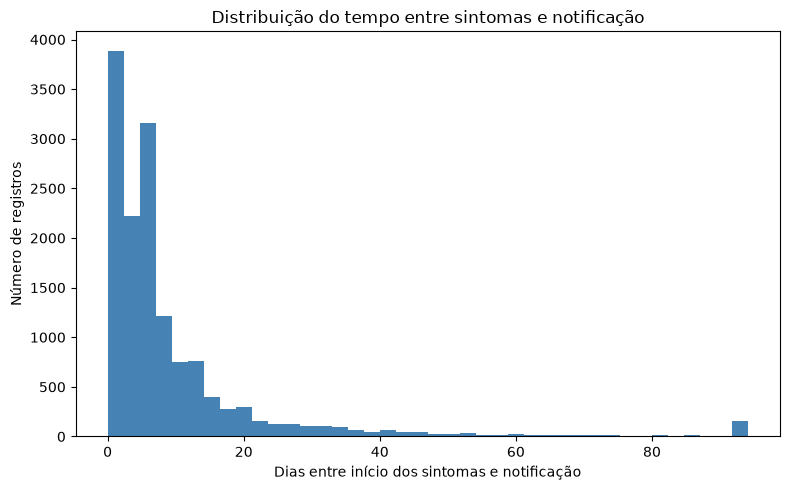

,TEMPO_SINTOMA_NOTIFICACAO
count,14390.000000
mean,10.218416
std,19.154214
min,0.000000
25%,2.000000
50%,6.000000
75%,10.000000
max,380.000000
fracao_negativa,0.000000


In [6]:
tempo_sintoma = df["TEMPO_SINTOMA_NOTIFICACAO"]

resumo_tempo_sintoma = tempo_sintoma.describe().to_frame(name="TEMPO_SINTOMA_NOTIFICACAO")
resumo_tempo_sintoma.loc["fracao_negativa"] = (tempo_sintoma < 0).mean()
resumo_tempo_sintoma.to_csv(RESULTS_DIR / "resumo_tempo_sintoma_notificacao.csv")

figura, eixo = plt.subplots(figsize=(8, 5))
eixo.hist(tempo_sintoma.clip(upper=tempo_sintoma.quantile(0.99)), bins=40, color="steelblue")
eixo.set_xlabel("Dias entre início dos sintomas e notificação")
eixo.set_ylabel("Número de registros")
eixo.set_title("Distribuição do tempo entre sintomas e notificação")
figura.tight_layout()
figura.savefig(PLOTS_DIR / "histograma_tempo_sintoma_notificacao.png", dpi=150)
plt.show()

resumo_tempo_sintoma

Calcula a completude de cada coluna de data por ano de notificação, para verificar se a qualidade do preenchimento mudou ao longo do período de 2020 a 2025.
A tabela é salva em `analysis/results_diagnostico/completude_datas_por_ano.csv` e representada em um gráfico de linhas em `analysis/plots/diagnostico/completude_datas_por_ano.png`.

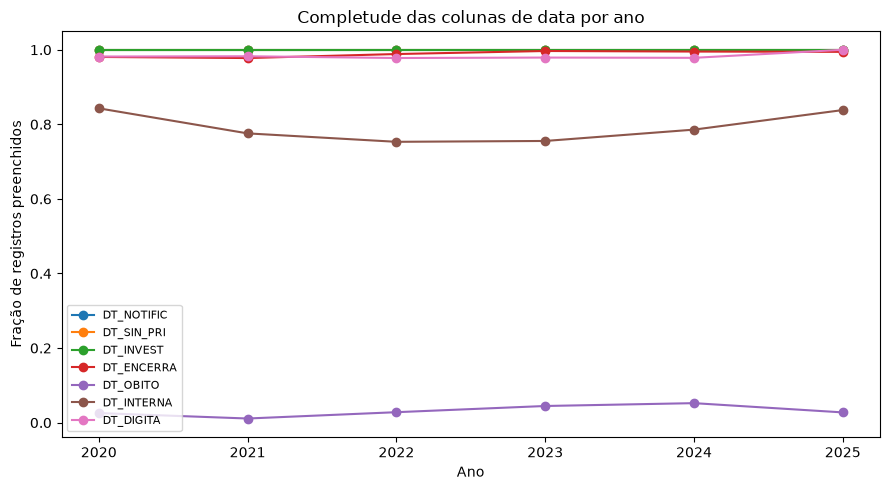

,DT_NOTIFIC,DT_SIN_PRI,DT_INVEST,DT_ENCERRA,DT_OBITO,DT_INTERNA,DT_DIGITA
year,,,,,,,
2020,1.0,1.0,1.0,0.980769,0.025641,0.842949,0.981838
2021,1.0,1.0,1.0,0.977813,0.011094,0.775753,0.982567
2022,1.0,1.0,1.0,0.988547,0.028041,0.753160,0.977883
2023,1.0,1.0,1.0,0.996723,0.044654,0.755428,0.979107
2024,1.0,1.0,1.0,0.995224,0.052288,0.785822,0.978381
2025,1.0,1.0,1.0,0.994446,0.027461,0.838322,1.000000


In [7]:
completude_por_ano = df.groupby("year")[DATE_COLS].apply(lambda bloco: bloco.notna().mean())
completude_por_ano.to_csv(RESULTS_DIR / "completude_datas_por_ano.csv")

figura, eixo = plt.subplots(figsize=(9, 5))
for coluna in DATE_COLS:
    eixo.plot(completude_por_ano.index, completude_por_ano[coluna], marker="o", label=coluna)
eixo.set_xlabel("Ano")
eixo.set_ylabel("Fração de registros preenchidos")
eixo.set_title("Completude das colunas de data por ano")
eixo.legend(loc="lower left", fontsize=8)
figura.tight_layout()
figura.savefig(PLOTS_DIR / "completude_datas_por_ano.png", dpi=150)
plt.show()

completude_por_ano

## Síntese dos achados

Nenhuma das sete colunas de data apresentou falha de conversão para datetime quando o valor estava preenchido, ou seja, todos os valores presentes seguem o formato AAAAMMDD esperado.
`DT_NOTIFIC`, `DT_SIN_PRI` e `DT_INVEST` estão preenchidas em todos os 14390 registros.
`DT_ENCERRA` e `DT_DIGITA` têm completude acima de 98 por cento em todos os anos.
`DT_OBITO` está preenchida em apenas 3,6 por cento dos registros, o que é esperado, pois só se aplica aos casos que evoluíram para óbito.
`DT_INTERNA` é a coluna menos completa, com completude entre 75 e 84 por cento ao longo dos anos, sem tendência clara de melhora ou piora entre 2020 e 2025.

Nas verificações de consistência lógica, nenhum caso teve `DT_SIN_PRI` posterior a `DT_NOTIFIC`.
Apenas 2 dos 14270 casos com `DT_ENCERRA` preenchida, uma fração próxima de zero, têm `DT_NOTIFIC` posterior ao encerramento.
Já `DT_INTERNA` caiu fora da janela plausível de 30 dias antes a 60 dias depois de `DT_NOTIFIC` em 515 dos 11362 casos preenchidos, cerca de 4,5 por cento, incluindo casos com diferenças de milhares de dias que sugerem erro de digitação no ano da data de internação.

A relação entre `DT_OBITO` e o alvo `obito` é íntegra, os 515 casos com `obito` igual a 1 têm `DT_OBITO` preenchida, e nenhum dos 13875 casos com `obito` igual a 0 tem `DT_OBITO` preenchida.
Apenas 1 dos 515 óbitos tem `DT_OBITO` posterior a `DT_ENCERRA`.

O tempo entre início dos sintomas e notificação, `TEMPO_SINTOMA_NOTIFICACAO`, tem mediana de 6 dias e média de aproximadamente 10,2 dias, com mínimo igual a 0 e nenhum valor negativo nos dados atuais, ou seja, não há caso de notificação registrada antes do início dos sintomas neste dataset.
O máximo observado é de 380 dias, um valor atipicamente alto que indica possível atraso real de notificação ou erro de registro em um número pequeno de casos.